# 1. Four-week department expense forecasting

We combine each department's transactions into Sunday-to-Saturday weeks. A single
Linear Regression model learns four outputs: the totals for the next four weeks.
The inputs are the last four known weekly totals and the department category.

The CSV files do not say whether an absent record means no spending or missing
collection. We keep absent department-weeks as unknown, rather than setting them
to zero. We also conservatively exclude weeks that extend outside the file's
observed date range. This uses the dataset's coverage, not today's date.
Training uses Approved requests, excluding the 13 employees omitted from the final seed. Original historical dates and SAR amounts are unchanged. Seed expenses are checked separately and are never appended to training.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.base import clone
from sklearn.multioutput import MultiOutputRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from importlib.metadata import version
from IPython.display import display

# Support Jupyter started from ml/notebooks, ml, or the repository root.
data_candidates = [Path('../data'), Path('data'), Path('ml/data')]
data_folder = next((folder for folder in data_candidates
                    if (folder / 'expenses.csv').exists()), None)
if data_folder is None:
    raise FileNotFoundError('Cannot find expenses.csv in ml/data.')
if not (data_folder / 'requests.csv').exists():
    raise FileNotFoundError(
        'requests.csv is missing from ml/data. The longer training history is required; '
        'do not substitute the 26-week seed dataset.'
    )

requests = pd.read_csv(data_folder / 'requests.csv')
seed_expenses = pd.read_csv(data_folder / 'expenses.csv')
departments = pd.read_csv(data_folder / 'departments.csv')

# Inspect actual CSV schemas before parsing dates or normalizing column names.
for filename, frame in [('requests.csv', requests), ('expenses.csv', seed_expenses),
                        ('departments.csv', departments)]:
    print(f'{filename}: {len(frame):,} rows')
    display(frame.dtypes.rename('Data type').to_frame())

# The local file currently uses department_id; also support the final id schema.
if 'department_id' not in departments.columns:
    departments = departments.rename(columns={'id': 'department_id'})
requests['expense_date'] = pd.to_datetime(requests['expense_date'], errors='raise')
seed_expenses['expense_date'] = pd.to_datetime(seed_expenses['expense_date'], errors='raise')

excluded_employee_ids = [
    1194, 1237, 1752, 1759, 2712,
    4097, 4438, 4481, 4851, 5060,
    5112, 5438, 5571
]
approved_requests = requests[requests['status'].eq('Approved')].copy()
expenses = approved_requests[
    ~approved_requests['requester_id'].isin(excluded_employee_ids)
].copy()


requests.csv: 247,838 rows


,Data type
expense_id,int64
requester_id,int64
department_id,int64
category,object
amount_sar,float64
amount_usd,float64
expense_date,object
description,object
status,object
created_at,object


expenses.csv: 106,618 rows


,Data type
id,int64
requester_id,int64
department_id,int64
category_id,int64
amount,float64
description,object
expense_date,object
status,object
reviewed_by,int64
reviewed_at,object


departments.csv: 20 rows


,Data type
department_id,int64
name,object
manager_id,int64
agency_number,int64


In [2]:
summary_rows = []
for label, frame in [('Before employee exclusion (Approved)', approved_requests),
                     ('After employee exclusion (Approved)', expenses)]:
    days = frame['expense_date'].dt.normalize()
    starts = days - pd.to_timedelta((days.dt.dayofweek + 1) % 7, unit='D')
    first_complete = starts.min()
    if first_complete < days.min():
        first_complete += pd.Timedelta(weeks=1)
    last_complete = starts.max()
    if last_complete + pd.Timedelta(days=6) > days.max():
        last_complete -= pd.Timedelta(weeks=1)
    summary_rows.append({
        'Historical data': label,
        'Transactions': len(frame),
        'First date': days.min().date(),
        'Last date': days.max().date(),
        'Departments': frame['department_id'].nunique(),
        'Completed weeks': len(pd.date_range(first_complete, last_complete, freq='W-SUN'))
    })
data_summary = pd.DataFrame(summary_rows)
display(data_summary)
print('Completed weeks count the calendar coverage; missing department-weeks stay unknown.')
print('Transactions excluded by employee ID:', len(approved_requests) - len(expenses))
print('No additional transactions or outliers removed from the Approved history.')


,Historical data,Transactions,First date,Last date,Departments,Completed weeks
0,Before employee exclusion (Approved),247838,2025-05-14,2026-06-28,20,58
1,After employee exclusion (Approved),209012,2025-05-14,2026-06-28,20,58


Completed weeks count the calendar coverage; missing department-weeks stay unknown.
Transactions excluded by employee ID: 38826
No additional transactions or outliers removed from the Approved history.


### Check the database seed against the original history
Match `expenses.id` to `requests.expense_id` to verify the unchanged SAR amounts,
requesters, departments, Approved status, and the 21-week date shift. The shift
is checked here only; training dates are not shifted. All checks must pass.


In [3]:
assert requests['expense_id'].is_unique, 'Historical expense IDs must be unique.'
assert seed_expenses['id'].is_unique, 'Seed expense IDs must be unique.'
seed_matches = seed_expenses.merge(
    requests, left_on='id', right_on='expense_id', how='left',
    suffixes=('_seed', '_history'), indicator=True, validate='one_to_one'
)
metadata_ids = set(departments['department_id'])
training_ids = set(expenses['department_id'])
seed_ids = set(seed_expenses['department_id'])
seed_date_shifts = seed_matches['expense_date_seed'] - seed_matches['expense_date_history']
# Current date in the project's timezone; seed records must be historical.
today = pd.Timestamp.now(tz='Asia/Riyadh').normalize().tz_localize(None)
seed_checks = pd.Series({
    'Exactly the same 20 department IDs': (
        len(departments) == len(metadata_ids) == 20
        and metadata_ids == training_ids == seed_ids
    ),
    'Every seed ID matches historical data': seed_matches['_merge'].eq('both').all(),
    'Same requester and department per expense': (
        seed_matches['requester_id_seed'].eq(seed_matches['requester_id_history']).all()
        and seed_matches['department_id_seed'].eq(seed_matches['department_id_history']).all()
    ),
    'Seed amount already equals historical amount_sar (no conversion)': np.isclose(
        seed_matches['amount'], seed_matches['amount_sar'], rtol=0, atol=0.005
    ).all(),
    'Seed and matched history are Approved': (
        seed_matches['status_seed'].eq('Approved').all()
        and seed_matches['status_history'].eq('Approved').all()
    ),
    'Excluded employees absent from seed': (
        not seed_expenses['requester_id'].isin(excluded_employee_ids).any()
    ),
    'Every seed date shifted forward 21 weeks (147 days)': (
        seed_date_shifts.eq(pd.Timedelta(days=147)).all()
    ),
    'Seed contains only historical dates': seed_expenses['expense_date'].max() < today
}, name='Passed')
display(seed_checks.to_frame())
assert seed_checks.all(), 'Seed consistency checks failed; inspect the results above.'
print('Seed date range:', seed_expenses['expense_date'].min().date(),
      'to', seed_expenses['expense_date'].max().date())
print('Verified shift:', seed_date_shifts.unique())


,Passed
Exactly the same 20 department IDs,True
Every seed ID matches historical data,True
Same requester and department per expense,True
Seed amount already equals historical amount_sar (no conversion),True
Seed and matched history are Approved,True
Excluded employees absent from seed,True
Every seed date shifted forward 21 weeks (147 days),True
Seed contains only historical dates,True


Seed date range: 2026-05-24 to 2026-11-22
Verified shift: <TimedeltaArray>
['147 days']
Length: 1, dtype: timedelta64[ns]


In [4]:
# A Sunday has dayofweek 6, so this gives its offset as zero.
expense_days = expenses['expense_date'].dt.normalize()
days_since_sunday = (expense_days.dt.dayofweek + 1) % 7
expenses['week_start'] = expense_days - pd.to_timedelta(days_since_sunday, unit='D')

first_day = expense_days.min()
last_day = expense_days.max()

first_week = expenses['week_start'].min()
if first_week < first_day:
    first_week = first_week + pd.Timedelta(weeks=1)

last_week = expenses['week_start'].max()
if last_week + pd.Timedelta(days=6) > last_day:
    last_week = last_week - pd.Timedelta(weeks=1)

complete_expenses = expenses[
    expenses['week_start'].between(first_week, last_week)
]
weekly = complete_expenses.groupby(
    ['week_start', 'department_id']
)['amount_sar'].sum().unstack('department_id')

In [5]:
# Keep every calendar week so a lag cannot accidentally skip a missing week.
week_dates = pd.date_range(first_week, last_week, freq='W-SUN')
weekly = weekly.reindex(index=week_dates, columns=departments['department_id'])
weekly.index.name = 'week_start'

missing_weeks = weekly.isna().sum()
print('Missing department-weeks:', int(missing_weeks.sum()))
print('Missing weeks remain unknown; samples needing them will be excluded.')
print('Weekly coverage:', first_week.date(), 'to', last_week.date())
print('Departments:', len(departments))

Missing department-weeks: 98
Missing weeks remain unknown; samples needing them will be excluded.
Weekly coverage: 2025-05-18 to 2026-06-21
Departments: 20


In [6]:
# departments with the most missing weeks
print(missing_weeks.sort_values(ascending=False))

department_id
20    6
10    5
18    5
17    5
16    5
15    5
14    5
13    5
12    5
1     5
9     5
8     5
7     5
6     5
5     5
3     5
11    5
2     4
4     4
19    4
dtype: int64


In [7]:
# Weeks with the highest number of missing sections
print(weekly.isna().sum(axis=1))

week_start
2025-05-18    20
2025-05-25    20
2025-06-01    20
2025-06-08    20
2025-06-15    17
2025-06-22     0
2025-06-29     0
2025-07-06     0
2025-07-13     0
2025-07-20     0
2025-07-27     0
2025-08-03     0
2025-08-10     0
2025-08-17     0
2025-08-24     0
2025-08-31     0
2025-09-07     0
2025-09-14     0
2025-09-21     0
2025-09-28     0
2025-10-05     0
2025-10-12     0
2025-10-19     0
2025-10-26     0
2025-11-02     0
2025-11-09     0
2025-11-16     0
2025-11-23     0
2025-11-30     0
2025-12-07     0
2025-12-14     0
2025-12-21     1
2025-12-28     0
2026-01-04     0
2026-01-11     0
2026-01-18     0
2026-01-25     0
2026-02-01     0
2026-02-08     0
2026-02-15     0
2026-02-22     0
2026-03-01     0
2026-03-08     0
2026-03-15     0
2026-03-22     0
2026-03-29     0
2026-04-05     0
2026-04-12     0
2026-04-19     0
2026-04-26     0
2026-05-03     0
2026-05-10     0
2026-05-17     0
2026-05-24     0
2026-05-31     0
2026-06-07     0
2026-06-14     0
2026-06-21     0
Fre

Each training row is dated by its first forecast week. `lag_1` is the week just
before that date, and `lag_4` is four weeks before it. The four targets begin at
that date. The forecast origin is the start date of the most recent completed
week; we make the forecast after that week ends.

In [8]:
sample_parts = []

for department_id in departments['department_id']:
    totals = weekly[department_id]
    department_samples = pd.DataFrame(index=weekly.index)
    department_samples['department_id'] = department_id

    for lag in range(1, 5):
        department_samples[f'lag_{lag}'] = totals.shift(lag)

    for horizon in range(1, 5):
        department_samples[f'target_{horizon}'] = totals.shift(-(horizon - 1))
    

    department_samples['origin_week'] = weekly.index - pd.Timedelta(weeks=1)
    department_samples['target_end_week'] = weekly.index + pd.Timedelta(weeks=3)
    sample_parts.append(department_samples)

samples = pd.concat(sample_parts).dropna().reset_index(drop=True)
lag_columns = ['lag_1', 'lag_2', 'lag_3', 'lag_4']
target_columns = ['target_1', 'target_2', 'target_3', 'target_4']
print('Usable training examples:', len(samples))

Usable training examples: 915


In [9]:
# Dummy columns treat department IDs as categories, not numeric quantities.
# The category list comes from department metadata, not future spending.
department_categories = departments['department_id'].tolist()
samples['department_id'] = pd.Categorical(
    samples['department_id'], categories=department_categories
)
X = pd.get_dummies(
    samples[lag_columns + ['department_id']],
    columns=['department_id'], drop_first=True, dtype=float
)
y = samples[target_columns]

# All these targets are within the completed historical weeks.
model = LinearRegression()
model.fit(X, y)

LinearRegression()

Model export is disabled while the new results are reviewed. The existing
`ml/models/forecasting.joblib` is not written. Models in this notebook stay in memory.


# 2. Rolling Validation

All five methods use the same expanding-window training rows, 12 validation
origins, departments, and four forecast horizons (960 observations). An origin
names the last completed Sunday-to-Saturday week; predictions are made after
that week ends. Training targets must all be known by then. Overlapping forecast
windows are evaluated separately. The original eligibility rule is unchanged.

XGBoost uses one regressor per target through `MultiOutputRegressor`. CatBoost
uses native `MultiRMSE` with the same one-hot features. Parameters below are fixed
before evaluation; there is no early stopping or tuning on validation targets.
Raw predictions are evaluated for all models. Training uses CPU only.

API references: [XGBoost](https://xgboost.readthedocs.io/en/stable/python/python_api.html),
[MultiOutputRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.multioutput.MultiOutputRegressor.html),
[CatBoost MultiRMSE](https://catboost.ai/docs/en/concepts/loss-functions-multiregression).


In [10]:
# Fixed starting parameters; limit CPU threads for this small dataset.
xgboost_params = dict(
    n_estimators=200, max_depth=3, learning_rate=0.05,
    subsample=0.9, colsample_bytree=0.9,
    objective='reg:squarederror', tree_method='hist', random_state=42,
    n_jobs=1, device='cpu'
)
catboost_params = dict(
    iterations=300, depth=4, learning_rate=0.05,
    loss_function='MultiRMSE', random_seed=42,
    verbose=False, allow_writing_files=False, thread_count=1, task_type='CPU'
)
# clone() creates a fresh, unfitted estimator at every validation origin.
model_templates = {
    'linear_regression': LinearRegression(),
    'random_forest': RandomForestRegressor(n_estimators=100, random_state=42),
    'xgboost': MultiOutputRegressor(XGBRegressor(**xgboost_params), n_jobs=1),
    'catboost': CatBoostRegressor(**catboost_params)
}
model_names = {
    'baseline': 'Last-Week Baseline',
    'linear_regression': 'Linear Regression',
    'random_forest': 'Random Forest Regressor',
    'xgboost': 'XGBoost Regressor',
    'catboost': 'CatBoost Regressor'
}
print('Python package versions:')
for package in ['numpy', 'pandas', 'scikit-learn', 'xgboost', 'catboost', 'matplotlib']:
    print(f'{package}: {version(package)}')


Python package versions:
numpy: 1.26.4
pandas: 2.2.2
scikit-learn: 1.6.1
xgboost: 3.2.0
catboost: 1.2.10
matplotlib: 3.9.1.post1


In [11]:
eligible_origins = []

for origin in sorted(samples['origin_week'].unique()):
    train_mask = samples['target_end_week'] <= origin
    validation_mask = samples['origin_week'] == origin
    validation_departments = samples.loc[validation_mask, 'department_id'].nunique()

    if train_mask.any() and validation_departments == len(departments):
        eligible_origins.append(origin)

validation_origins = eligible_origins[-12:]
if len(validation_origins) == 0:
    raise ValueError('Not enough complete weekly history for rolling validation.')

print('Rolling validation origins:', len(validation_origins))
print('First origin:', pd.Timestamp(validation_origins[0]).date())
print('Last origin:', pd.Timestamp(validation_origins[-1]).date())
# Guard the existing experiment's origins rather than selecting new ones.
expected_origins = pd.date_range('2026-03-08', periods=12, freq='W-SUN')
assert list(pd.to_datetime(validation_origins)) == list(expected_origins), (
    'Validation origins changed; inspect the data before comparing experiments.'
)


Rolling validation origins: 12
First origin: 2026-03-08
Last origin: 2026-05-24


In [12]:
validation_parts = []

for origin in validation_origins:
    # The complete four-week training target must already be known.
    train_mask = samples['target_end_week'] <= origin
    validation_mask = samples['origin_week'] == origin
    assert samples.loc[train_mask, 'target_end_week'].max() <= origin
    assert samples.loc[validation_mask, 'department_id'].nunique() == 20
    assert len(X.loc[validation_mask]) == 20

    predictions = {}
    for model_key, template in model_templates.items():
        rolling_model = clone(template)
        rolling_model.fit(X.loc[train_mask], y.loc[train_mask])
        predictions[model_key] = rolling_model.predict(X.loc[validation_mask])
        assert predictions[model_key].shape == (20, 4)
        assert np.isfinite(predictions[model_key]).all()

    actual_values = y.loc[validation_mask].to_numpy()
    baseline_values = samples.loc[validation_mask, 'lag_1'].to_numpy()
    department_ids = samples.loc[validation_mask, 'department_id'].to_numpy()

    for horizon in range(1, 5):
        horizon_results = pd.DataFrame({
            'origin_week': origin,
            'department_id': department_ids,
            'horizon': horizon,
            'forecast_week': origin + pd.Timedelta(weeks=horizon),
            'actual': actual_values[:, horizon - 1],
            'baseline': baseline_values
        })
        for model_key, values in predictions.items():
            horizon_results[model_key] = values[:, horizon - 1]
        validation_parts.append(horizon_results)
    print('Completed validation origin:', pd.Timestamp(origin).date())

validation_results = pd.concat(validation_parts, ignore_index=True)
assert len(validation_results) == 960
assert not validation_results.duplicated(['origin_week', 'department_id', 'horizon']).any()
assert validation_results[list(model_names)].notna().all().all()
print('Evaluated department/week/horizon observations per model:', len(validation_results))


Got unsafe target value = 1.12282e+06 at object #0 of dataset learn
Got unsafe target value = 1.047e+06 at object #0 of dataset learn
Got unsafe target value = 1.14581e+06 at object #0 of dataset learn
Got unsafe target value = 1.23453e+06 at object #0 of dataset learn


Completed validation origin: 2026-03-08


Got unsafe target value = 1.12282e+06 at object #0 of dataset learn
Got unsafe target value = 1.047e+06 at object #0 of dataset learn
Got unsafe target value = 1.14581e+06 at object #0 of dataset learn
Got unsafe target value = 1.23453e+06 at object #0 of dataset learn


Completed validation origin: 2026-03-15


Got unsafe target value = 1.12282e+06 at object #0 of dataset learn
Got unsafe target value = 1.047e+06 at object #0 of dataset learn
Got unsafe target value = 1.14581e+06 at object #0 of dataset learn
Got unsafe target value = 1.23453e+06 at object #0 of dataset learn


Completed validation origin: 2026-03-22


... (14 outputs left out)

Got unsafe target value = 1.12282e+06 at object #0 of dataset learn
Got unsafe target value = 1.047e+06 at object #0 of dataset learn
Got unsafe target value = 1.14581e+06 at object #0 of dataset learn
Got unsafe target value = 1.23453e+06 at object #0 of dataset learn


Completed validation origin: 2026-05-17


Got unsafe target value = 1.12282e+06 at object #0 of dataset learn
Got unsafe target value = 1.047e+06 at object #0 of dataset learn
Got unsafe target value = 1.14581e+06 at object #0 of dataset learn
Got unsafe target value = 1.23453e+06 at object #0 of dataset learn


Completed validation origin: 2026-05-24
Evaluated department/week/horizon observations per model: 960


# 3. Numeric MAE Target

MAE is the average size of an error in SAR; smaller is better. Overall MAE treats
every department, forecast origin, and horizon equally. We also calculate MAE for
each of the four horizons. We keep full precision for calculations and round
only the displayed tables.

Our numeric target is 90% of the overall baseline MAE. A model achieves
the target if its overall MAE is at or below that value (at least 10% improvement
when baseline MAE is positive).

A positive percentage improvement means a lower MAE; a negative value means a
higher MAE. Percentage improvement is undefined when the reference MAE is zero,
so we show NaN in that case.

In [13]:
mae_by_model = {
    key: mean_absolute_error(validation_results['actual'], validation_results[key])
    for key in model_names
}
baseline_mae = mae_by_model['baseline']
regression_mae = mae_by_model['linear_regression']
forest_mae = mae_by_model['random_forest']
mae_target = 0.90 * baseline_mae
comparison = pd.DataFrame({
    'Model': list(model_names.values()),
    'MAE (SAR)': list(mae_by_model.values())
})
comparison['Improvement vs. Baseline (%)'] = (
    100 * (baseline_mae - comparison['MAE (SAR)']) / baseline_mae
    if baseline_mae > 0 else np.nan
)
comparison['Improvement vs. Linear Regression (%)'] = (
    100 * (regression_mae - comparison['MAE (SAR)']) / regression_mae
    if regression_mae > 0 else np.nan
)
comparison['Numeric MAE Target (SAR)'] = mae_target
comparison['Target Achieved'] = comparison['MAE (SAR)'] <= mae_target
comparison = comparison.sort_values('MAE (SAR)', kind='stable').reset_index(drop=True)
best_mae = comparison['MAE (SAR)'].min()
best_models = comparison.loc[comparison['MAE (SAR)'] == best_mae, 'Model']
with pd.option_context('display.max_columns', None, 'display.width', 200):
    display(comparison.round(2))
print('Lowest overall MAE:', ', '.join(best_models), f'({best_mae:,.2f} SAR)')


,Model,MAE (SAR),Improvement vs. Baseline (%),Improvement vs. Linear Regression (%),Numeric MAE Target (SAR),Target Achieved
0,Linear Regression,111814.81,4.44,0.00,105311.93,False
1,Last-Week Baseline,117013.25,0.00,-4.65,105311.93,False
2,Random Forest Regressor,117780.40,-0.66,-5.34,105311.93,False
3,CatBoost Regressor,120408.07,-2.90,-7.69,105311.93,False
4,XGBoost Regressor,127911.83,-9.31,-14.40,105311.93,False


Lowest overall MAE: Linear Regression (111,814.81 SAR)


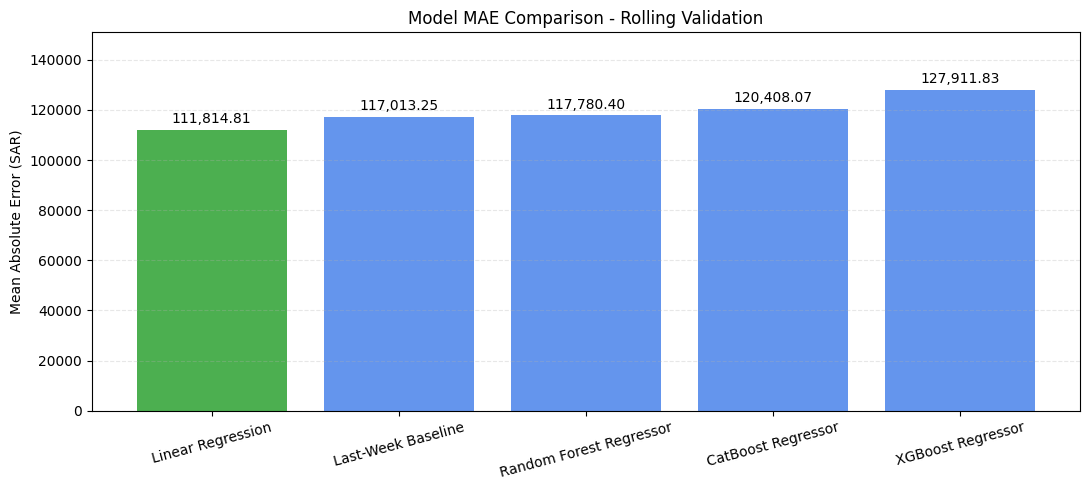

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 5))
colors = ['#4CAF50' if value == best_mae else '#6495ED'
          for value in comparison['MAE (SAR)']]
bars = ax.bar(comparison['Model'], comparison['MAE (SAR)'], color=colors)
for bar in bars:
    ax.annotate(f'{bar.get_height():,.2f}',
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 5), textcoords='offset points', ha='center')
ax.set_title('Model MAE Comparison - Rolling Validation')
ax.set_ylabel('Mean Absolute Error (SAR)')
ax.set_ylim(0, max(comparison['MAE (SAR)'].max() * 1.18, 1))
ax.tick_params(axis='x', labelrotation=15)
ax.grid(axis='y', linestyle='--', alpha=0.3)
fig.tight_layout()
plt.show()


MAE by forecast horizon (all amounts in SAR):


,Horizon,Last-Week Baseline,Linear Regression,Random Forest Regressor,XGBoost Regressor,CatBoost Regressor
0,Week 1,114244.78,108868.56,104727.30,124027.35,101936.51
1,Week 2,120147.89,113679.52,121229.60,132760.54,122014.89
2,Week 3,125990.09,112825.44,123788.16,135389.65,132168.33
3,Week 4,107670.25,111885.69,121376.52,119469.80,125512.55


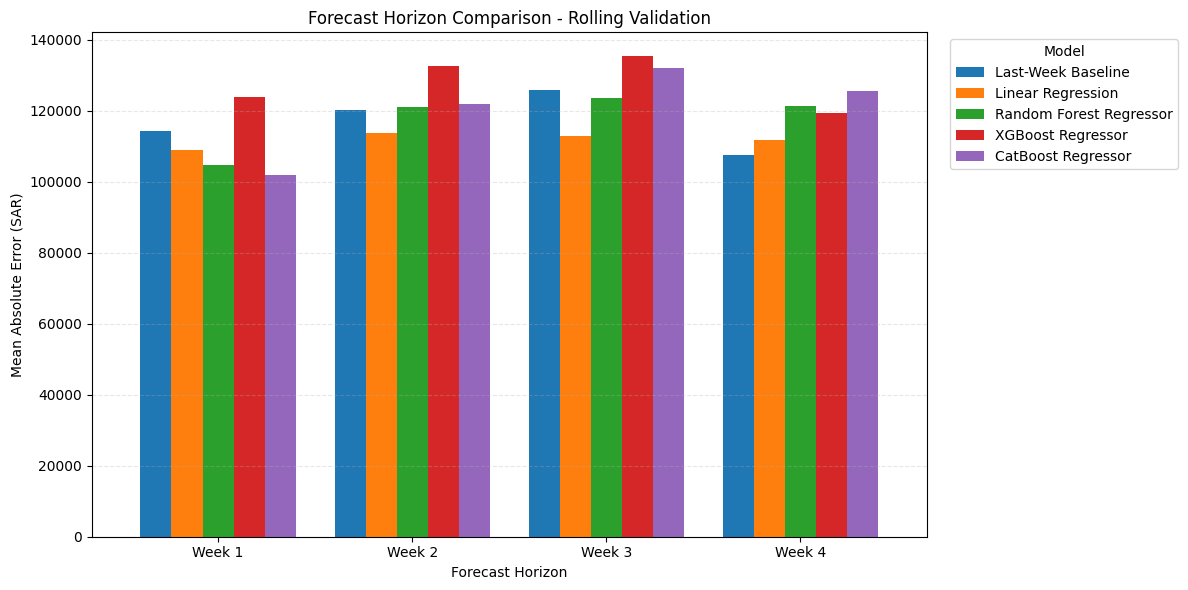

In [15]:
horizon_rows = []
for horizon in range(1, 5):
    results = validation_results[validation_results['horizon'] == horizon]
    row = {'Horizon': f'Week {horizon}'}
    for key, name in model_names.items():
        row[name] = mean_absolute_error(results['actual'], results[key])
    horizon_rows.append(row)
horizon_comparison = pd.DataFrame(horizon_rows)
print('MAE by forecast horizon (all amounts in SAR):')
with pd.option_context('display.max_columns', None, 'display.width', 200):
    display(horizon_comparison.round(2))

ax = horizon_comparison.set_index('Horizon').plot.bar(figsize=(12, 6), width=0.8)
ax.set_title('Forecast Horizon Comparison - Rolling Validation')
ax.set_xlabel('Forecast Horizon')
ax.set_ylabel('Mean Absolute Error (SAR)')
ax.tick_params(axis='x', labelrotation=0)
ax.legend(title='Model', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


# 4. Select and refit the best model
Use the lowest unrounded rolling-validation MAE, including the baseline. If tied,
use the first model in the comparison table. Refit a selected learned model on all
usable historical examples; retain raw predictions as in the existing evaluation.
Selection uses this validation set, so this is not an independent test estimate.
No model is exported.


**Experiment interpretation:** Linear Regression has the lowest overall MAE
(111,814.81 SAR), improving on the baseline by 4.44%. None of the five methods
meets the 105,311.93 SAR target. CatBoost has the best Week 1 MAE (101,936.51 SAR),
but its errors increase at longer horizons. XGBoost is worse than Linear
Regression at every horizon. These fixed starting parameters therefore do not
improve overall accuracy on this validation period.

A possible explanation is that the simpler linear model generalizes better from
this small weekly dataset (915 usable historical examples in total, fewer at
each validation origin). The experiment does not establish the cause or show
that boosting cannot improve with other settings. No tuning was performed, and
model selection on these overlapping validation windows is not an independent
final test. Tested dependency versions are in `ml/requirements-notebooks.txt`.


In [16]:
selected_model_name = comparison.loc[0, 'Model']
selected_key = next(key for key, name in model_names.items() if name == selected_model_name)
if selected_key == 'baseline':
    selected_model = None  # Last-Week Baseline requires no fitting.
    selected_parameters = {'strategy': 'repeat lag_1 for all four horizons'}
else:
    selected_model = clone(model_templates[selected_key])
    selected_model.fit(X, y)
    selected_parameters = selected_model.get_params(deep=False).copy()
    if selected_key == 'xgboost':
        selected_parameters = {'wrapper': 'MultiOutputRegressor', 'n_jobs': 1,
                               'estimator': selected_model.estimator.get_params()}

print('Best model:', selected_model_name)
print('Hyperparameters:', selected_parameters)
print(f'Overall rolling-validation MAE: {best_mae:,.2f} SAR')
print(f"Improvement over Linear Regression: {comparison.loc[0, 'Improvement vs. Linear Regression (%)']:.2f}%")
print(f"Improvement over baseline: {comparison.loc[0, 'Improvement vs. Baseline (%)']:.2f}%")
print('Historical training examples:', len(X))
print('Model retained in memory only; forecasting.joblib is unchanged.')


Best model: Linear Regression
Hyperparameters: {'copy_X': True, 'fit_intercept': True, 'n_jobs': None, 'positive': False}
Overall rolling-validation MAE: 111,814.81 SAR
Improvement over Linear Regression: 0.00%
Improvement over baseline: 4.44%
Historical training examples: 915
Model retained in memory only; forecasting.joblib is unchanged.


# 5. Example forecasts from the database seed (SAR)

These are separate from rolling validation. Use the selected model refitted on
all usable historical training examples, and the seed's latest four completed
Sunday-to-Saturday weeks as inputs. The seed is never used for fitting or MAE.
Missing department-weeks remain unknown. `lag_1` is newest and `lag_4` is oldest.
Forecast dates follow the seed's last completed week, rather than today's date.


In [17]:
# Repeat the same conservative coverage rules for the seed, independently.
seed_days = seed_expenses['expense_date'].dt.normalize()
seed_expenses['week_start'] = seed_days - pd.to_timedelta(
    (seed_days.dt.dayofweek + 1) % 7, unit='D'
)
seed_first_week = seed_expenses['week_start'].min()
if seed_first_week < seed_days.min():
    seed_first_week += pd.Timedelta(weeks=1)
seed_last_day = min(seed_days.max(), today - pd.Timedelta(days=1))
seed_last_week = seed_last_day - pd.Timedelta(days=(seed_last_day.dayofweek + 1) % 7)
if seed_last_week + pd.Timedelta(days=6) > seed_last_day:
    seed_last_week -= pd.Timedelta(weeks=1)

complete_seed = seed_expenses[
    seed_expenses['week_start'].between(seed_first_week, seed_last_week)
]
seed_weekly = complete_seed.groupby(
    ['week_start', 'department_id']
)['amount'].sum().unstack('department_id')
seed_weekly = seed_weekly.reindex(
    index=pd.date_range(seed_first_week, seed_last_week, freq='W-SUN'),
    columns=department_categories
)
seed_weekly.index.name = 'week_start'
print('Seed completed weeks:', len(seed_weekly))
print('Seed weekly coverage:', seed_first_week.date(), 'to', seed_last_week.date())
print('Latest partial week excluded; missing department-weeks:',
      int(seed_weekly.isna().sum().sum()))
print('Latest four seed weekly totals (SAR), oldest to newest:')
display(seed_weekly.tail(4).round(2))


Seed completed weeks: 26
Seed weekly coverage: 2026-05-24 to 2026-11-15
Latest partial week excluded; missing department-weeks: 0
Latest four seed weekly totals (SAR), oldest to newest:


department_id,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
week_start,,,,,,,,,,,,,,,,,,,,
2026-10-25,1187364.06,867332.72,684278.99,565814.34,543510.16,252711.05,636492.99,98996.68,53836.05,45046.65,119823.13,158790.75,188665.08,80258.19,70746.13,24351.76,126923.19,99707.42,51646.76,30261.62
2026-11-01,954617.70,1044769.60,749539.14,711801.27,1636901.00,482136.73,397072.70,141374.88,62478.22,144280.90,113957.81,166610.16,249478.31,72670.84,112556.60,16642.48,69631.50,83249.18,205365.47,26931.32
2026-11-08,1020659.56,1333415.74,642141.42,838890.90,339748.77,252055.35,1449724.28,154198.32,65943.33,136905.30,89709.37,388070.22,92477.60,69558.08,102619.51,26591.78,60734.39,229593.91,103897.76,22635.22
2026-11-15,1116823.88,691696.68,626743.33,863885.33,811413.63,286806.21,991191.46,57899.76,117282.91,96343.98,164468.47,128113.62,122632.84,94157.82,178477.35,16266.80,290833.72,389990.23,39472.26,6355.47


In [18]:
latest_inputs = pd.DataFrame({'department_id': departments['department_id']})

for lag in range(1, 5):
    lag_week = seed_last_week - pd.Timedelta(weeks=lag - 1)
    latest_inputs[f'lag_{lag}'] = latest_inputs['department_id'].map(seed_weekly.loc[lag_week])

if latest_inputs[lag_columns].isna().any().any():
    raise ValueError('Each department needs four recent known weeks to forecast.')

latest_inputs['department_id'] = pd.Categorical(
    latest_inputs['department_id'], categories=department_categories
)
latest_X = pd.get_dummies(
    latest_inputs[lag_columns + ['department_id']],
    columns=['department_id'], drop_first=True, dtype=float
)
latest_X = latest_X.reindex(columns=X.columns, fill_value=0)
if selected_model is None:
    future_predictions = np.repeat(latest_inputs['lag_1'].to_numpy()[:, None], 4, axis=1)
else:
    future_predictions = selected_model.predict(latest_X)
print('Seed forecast model:', selected_model_name)
print('Seed input totals (SAR); lag_1 is newest:')
display(latest_inputs[['department_id'] + lag_columns].round(2))

Seed forecast model: Linear Regression
Seed input totals (SAR); lag_1 is newest:


,department_id,lag_1,lag_2,lag_3,lag_4
0,1,1116823.88,1020659.56,954617.70,1187364.06
1,2,691696.68,1333415.74,1044769.60,867332.72
2,3,626743.33,642141.42,749539.14,684278.99
3,4,863885.33,838890.90,711801.27,565814.34
4,5,811413.63,339748.77,1636901.00,543510.16
5,6,286806.21,252055.35,482136.73,252711.05
6,7,991191.46,1449724.28,397072.70,636492.99
7,8,57899.76,154198.32,141374.88,98996.68
8,9,117282.91,65943.33,62478.22,53836.05
9,10,96343.98,136905.30,144280.90,45046.65


In [19]:
forecast_table = departments[['department_id', 'name']].copy()
for horizon in range(1, 5):
    forecast_table[f'Week {horizon} (SAR)'] = future_predictions[:, horizon - 1]

forecast_dates = pd.DataFrame({
    'Horizon': ['Week 1', 'Week 2', 'Week 3', 'Week 4'],
    'Week starts (Sunday)': [
        seed_last_week + pd.Timedelta(weeks=horizon) for horizon in range(1, 5)
    ]
})
display(forecast_dates)
display(forecast_table.round(2))

,Horizon,Week starts (Sunday)
0,Week 1,2026-11-22
1,Week 2,2026-11-29
2,Week 3,2026-12-06
3,Week 4,2026-12-13


,department_id,name,Week 1 (SAR),Week 2 (SAR),Week 3 (SAR),Week 4 (SAR)
0,1,Operations,1060190.47,1031592.96,1056538.19,1028853.01
1,2,Business Development,846369.99,972591.17,880560.20,815630.40
2,3,Research & Development,649530.41,640413.26,619588.43,613034.52
3,4,Facilities Management,602504.14,616817.58,650138.76,627909.09
4,5,Fleet & Logistics,918115.69,774912.14,697667.74,834780.37
5,6,Projects,261998.33,240726.71,215286.14,216442.91
6,7,Engineering,934085.53,1112057.72,1185011.27,1149665.37
7,8,Field Services,85023.27,101725.19,84328.46,73245.59
8,9,Hospitality & Events,76171.15,70029.19,82112.98,85852.05
9,10,Security,104571.64,116465.92,108032.82,115648.74


### Last-Week Baseline example from the same seed inputs

Repeat the most recent completed seed total for all four horizons, in SAR.
This example is separate from the historical rolling-validation MAE above.


In [20]:
last_week_values = latest_inputs['lag_1'].to_numpy()
baseline_predictions = np.repeat(last_week_values[:, None], 4, axis=1)

baseline_table = departments[['department_id', 'name']].copy()
for horizon in range(1, 5):
    baseline_table[f'Week {horizon} (SAR)'] = baseline_predictions[:, horizon - 1]

display(baseline_table.round(2))

,department_id,name,Week 1 (SAR),Week 2 (SAR),Week 3 (SAR),Week 4 (SAR)
0,1,Operations,1116823.88,1116823.88,1116823.88,1116823.88
1,2,Business Development,691696.68,691696.68,691696.68,691696.68
2,3,Research & Development,626743.33,626743.33,626743.33,626743.33
3,4,Facilities Management,863885.33,863885.33,863885.33,863885.33
4,5,Fleet & Logistics,811413.63,811413.63,811413.63,811413.63
5,6,Projects,286806.21,286806.21,286806.21,286806.21
6,7,Engineering,991191.46,991191.46,991191.46,991191.46
7,8,Field Services,57899.76,57899.76,57899.76,57899.76
8,9,Hospitality & Events,117282.91,117282.91,117282.91,117282.91
9,10,Security,96343.98,96343.98,96343.98,96343.98
